# Unsupervised Learning: Clustering & Dimensionality Reduction

This notebook explores unsupervised learning on three datasets:

1. **Dimensionality reduction with PCA**: Delta Air Lines fleet data (44 aircraft, 33 features), comparing naive vs. standardized PCA.
2. **K-Means clustering** on the principal components, choosing *k* with the elbow method and profiling the resulting aircraft segments.
3. **K-Means vs. DBSCAN vs. hierarchical clustering** on the Iris dataset, the Delta PCA components and daily stock-price movements of 60 companies.
4. **t-SNE and UMAP vs. PCA** for visualizing the Delta fleet.
5. **Hierarchical clustering** of the Delta fleet (dendrogram).

All datasets are in the `data/` folder.

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import umap

from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn.utils import check_random_state
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

## 1. Dimensionality Reduction with PCA

The goal of this section is to get a better understanding of dimensionality reduction with PCA, using Delta Air Lines fleet data. Delta and other major airlines publish data on all of their aircraft on their website ([e.g.](https://www.delta.com/content/www/en_US/traveling-with-us/airports-and-aircraft/Aircraft.html)).

The data set has 34 columns (including the names of the aircraft) on 44 aircraft. It includes both quantitative measurements, such as cruising speed, accommodation and range in miles, and categorical data, such as whether a particular aircraft has Wi-Fi or video. These binary variables are assigned values of either 1 or 0, for yes or no respectively.

In [2]:
df = pd.read_csv('data/delta.csv', index_col='Aircraft')

In [3]:
df.head()

,Seat Width (Club),Seat Pitch (Club),Seat (Club),Seat Width (First Class),Seat Pitch (First Class),Seats (First Class),Seat Width (Business),Seat Pitch (Business),Seats (Business),Seat Width (Eco Comfort),...,Video,Power,Satellite,Flat-bed,Sleeper,Club,First Class,Business,Eco Comfort,Economy
Aircraft,,,,,,,,,,,,,,,,,,,,,
Airbus A319,0.0,0,0,21.0,36.0,12,0.0,0.0,0,17.2,...,0,0,0,0,0,0,1,0,1,1
Airbus A319 VIP,19.4,44,12,19.4,40.0,28,21.0,59.0,14,0.0,...,1,0,0,0,0,1,1,1,0,0
Airbus A320,0.0,0,0,21.0,36.0,12,0.0,0.0,0,17.2,...,0,0,0,0,0,0,1,0,1,1
Airbus A320 32-R,0.0,0,0,21.0,36.0,12,0.0,0.0,0,17.2,...,0,0,0,0,0,0,1,0,1,1
Airbus A330-200,0.0,0,0,0.0,0.0,0,21.0,60.0,32,18.0,...,1,1,0,1,0,0,0,1,1,1


First, let's look at the attributes related to the aircraft's physical characteristics:

- Cruising Speed (mph)
- Range (miles)
- Engines
- Wingspan (ft)
- Tail Height (ft)
- Length (ft)

`plot_pairgrid()` visualizes these six attributes with histograms on the diagonal and scatter plots off the diagonal.

In [4]:
def plot_pairgrid(df):
    '''
    Uses seaborn.pairplot to visualize the attributes related to the six physical characteristics.
    Diagonal plots are histograms. The off-diagonal plots are scatter plots.
    
    Parameters
    ----------
    df: A pandas.DataFrame. Comes from importing delta.csv.
    
    Returns
    -------
    A seaborn.axisgrid.PairGrid instance.
    '''
    ax = sns.pairplot(
    df[["Cruising Speed (mph)", "Range (miles)", "Engines", "Wingspan (ft)", "Tail Height (ft)", "Length (ft)"]],
    diag_kind="hist",
    plot_kws={"alpha": 0.8, "s": 60},
    diag_kws={"bins": 10}
)

    return ax

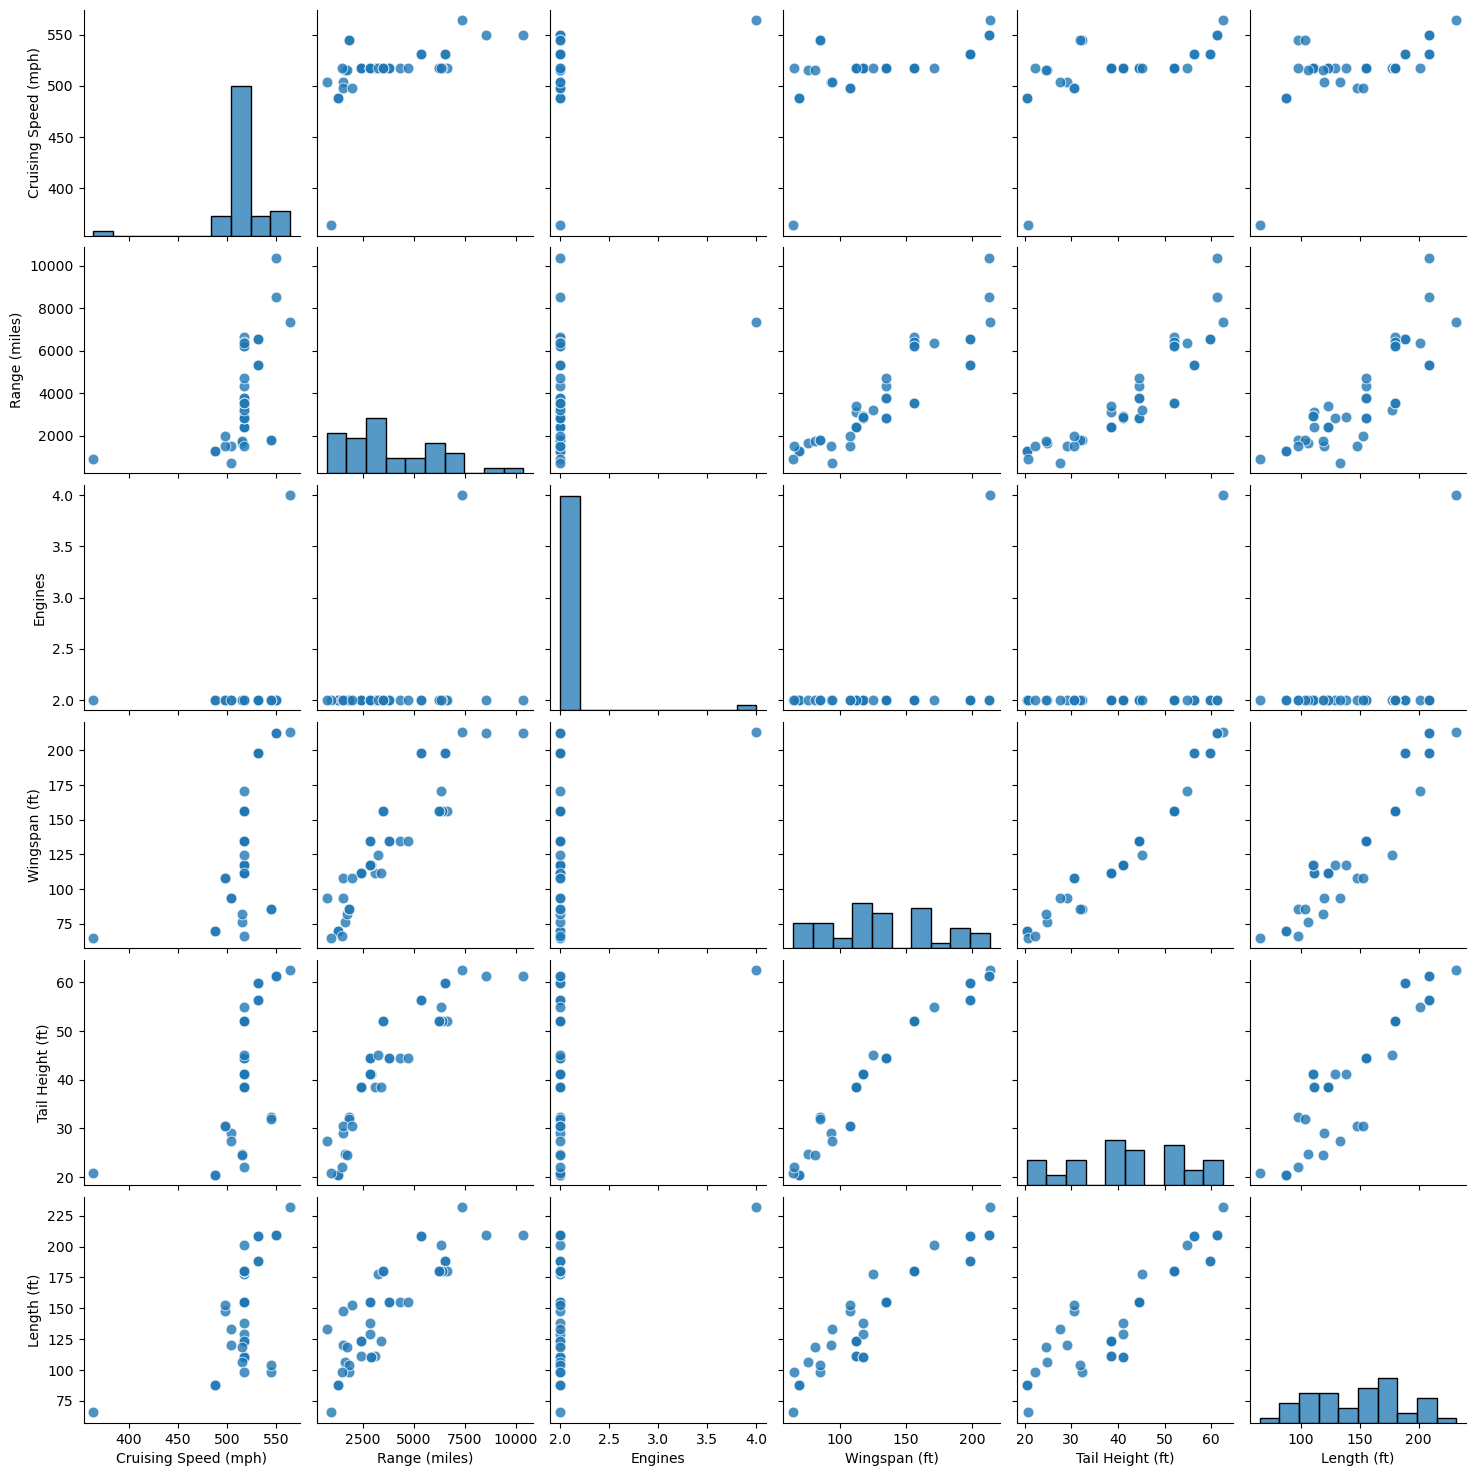

In [5]:
pg = plot_pairgrid(df)

We observe pretty strong positive correlations between all these variables, as most of them are related to the aircraft’s overall size. Remarkably there is an almost perfectly linear relationship between wingspan and tail height.

The exception here is engines. There is one outlier which has four engines, while all the other aircraft have two. In this way the engines variable is really more like a categorical variable, but we shall see as the analysis progresses that this is not really important, as there are other variables which more strongly discern the aircraft from one another than this.

#### Apply PCA
First, let's naively apply principal components to the raw (unscaled) data. `fit_pca()` fits a [sklearn.decomposition.PCA](http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) model on all values of the data frame.

In [6]:
def fit_pca(df, n_components):
    '''
    Uses sklearn.decomposition.PCA to fit a PCA model on "df".
    
    Parameters
    ----------
    df: A pandas.DataFrame. Comes from delta.csv.
    n_components: An int. Number of principal components to keep.
    
    Returns
    -------
    An sklearn.decomposition.pca.PCA instance.
    '''
    pca = PCA(n_components)
    pca = pca.fit(df)

    return pca

In [7]:
# keep all components by setting n_components to the number of columns in df
pca_naive = fit_pca(df, n_components=df.shape[1])

In [8]:
def plot_explained_variance(pca, title="PCA Explained Variance"):
    '''
    Plots the variance explained by each of the principal components.

    Parameters
    ----------
    pca: An sklearn.decomposition.PCA instance.
    title: Plot title.

    Returns
    -------
    A matplotlib.Axes instance.
    '''
    var_ratio = pca.explained_variance_ratio_

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(var_ratio)
    ax.set_xlabel("Dimensions #")
    ax.set_ylabel("Explained Variance Ratio")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

    return ax

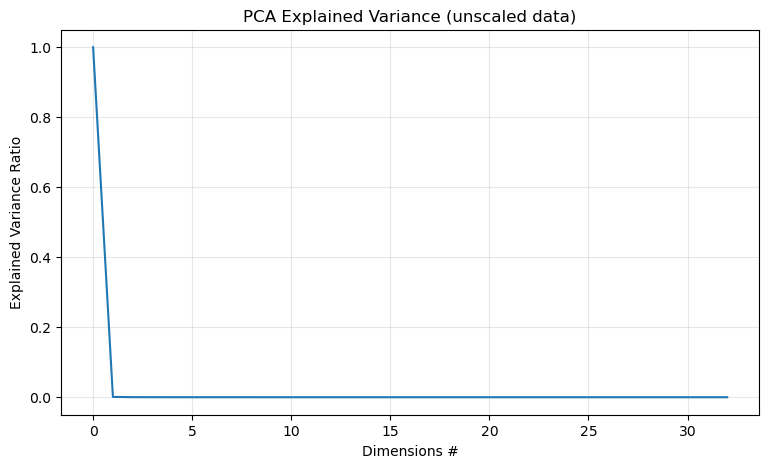

In [9]:
naive_var = plot_explained_variance(pca_naive, title="PCA Explained Variance (unscaled data)")

In [10]:
abs_val = np.abs(pca_naive.components_[0])
max_pos = abs_val.argmax()

print('The first principal component explains {0:.1%} of the variance.'.format(pca_naive.explained_variance_ratio_[0]))
print('Its largest loading is "{0}" ({1:0.3f}).'.format(df.columns[max_pos], abs_val[max_pos]))

The first principal component explains 99.9% of the variance.
Its largest loading is "Range (miles)" (0.999).


Taking this naive approach, we can see that the first principal component accounts for 99.9% of the variance in the data. Looking more closely, we can see that the first principal component is essentially just the range in miles. This is because the scales of the different variables in the data set vary widely.

PCA is a scale-dependent method. For example, if the range of one column is [-100, 100], while that of another column is [-0.1, 0.1], PCA will place more weight on the feature with larger values. One way to avoid this is to standardize the data set by scaling each feature to zero mean and unit variance.

`standardize()` uses scikit-learn's `StandardScaler` to do this.

In [11]:
def standardize(df):
    '''
    Uses sklearn.preprocessing.StandardScaler to make each features look like
    a Gaussian with zero mean and unit variance.
    
    Parameters
    ----------
    df: A pandas.DataFrame
    
    Returns
    -------
    A numpy array.
    '''
    scaled = StandardScaler().fit_transform(df)

    return scaled

In [12]:
scaled = standardize(df)

In [13]:
# keep only 10 components
n_components = 10
pca = fit_pca(scaled, n_components=n_components)

Let's take another look at the explained variance of the first 10 principal components, now on the scaled data.

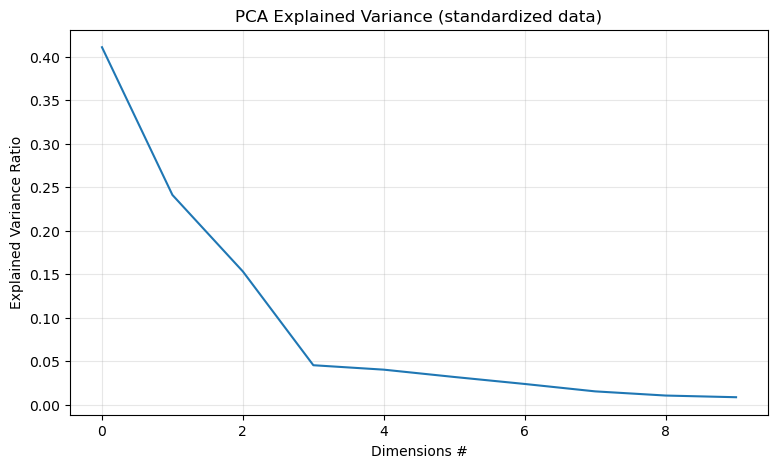

In [14]:
ax = plot_explained_variance(pca, title="PCA Explained Variance (standardized data)")

There are various rules of thumb for selecting the number of principal components to retain in an analysis of this type. One of them is:

> Pick the number of components which explain 85% or greater of the variation.

Here the first 4 principal components (0th, 1st, 2nd and 3rd) explain about 85% of the variance and the first 10 explain about 98%. The k-means model in the next section is fit on all 10 retained components, and the first four are used to visualize the clusters.

`reduce()` applies the fitted PCA model to the scaled data, projecting it onto the retained components.

In [15]:
def reduce(pca, array):
    '''
    Applies the `pca` model on array.
    
    Parameters
    ----------
    pca: An sklearn.decomposition.PCA instance.
    
    Returns
    -------
    A Numpy array
    '''
    reduced = pca.transform(array)

    return reduced

In [16]:
reduced = reduce(pca, scaled)
print(f"Reduced shape: {reduced.shape}, cumulative explained variance: {pca.explained_variance_ratio_.sum():.1%}")

Reduced shape: (44, 10), cumulative explained variance: 98.1%


## 2. K-Means Clustering

We now cluster the aircraft using the first 10 principal components of the standardized Delta data computed above.

`cluster()` fits a k-means model and returns a tuple of the fitted model and a 1-d array with the cluster each data point belongs to.

In [17]:
def cluster(array, random_state, n_clusters=4):
    '''
    Fits and predicts k-means clustering on "array"
    
    Parameters
    ----------
    array: A numpy array
    random_state: Random seed, e.g. check_random_state(0)
    n_clusters: The number of clusters. Default: 4
    
    Returns
    -------
    A tuple (sklearn.KMeans, np.ndarray)
    '''
    model = KMeans(
        n_clusters=n_clusters,
        random_state=random_state,
        n_init=10
    )

    clusters = model.fit_predict(array)

    # return the fitted model and the predicted cluster labels as a tuple
    return (model, clusters)

The scikit-learn documentation for [KMeans](http://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) exposes the inertia (within-cluster sum of squares) in the `inertia_` attribute. We vary the number of clusters, plot the inertia as a function of the number of clusters, and pick the "elbow" in the plot.

In [18]:
def plot_inertia(array, start=1, end=10):
    '''
    Increase the number of clusters from "start" to "end" (inclusive).
    Finds the inertia of k-means clustering for different k.
    Plots inertia as a function of the number of clusters.

    
    Parameters
    ----------
    array: A numpy array.
    start: An int. Default: 1
    end: An int. Default: 10
    
    Returns
    -------
    A matplotlib.Axes instance.
    '''
    x_axis = range(start, end + 1)
    inertia = []

    for k in x_axis:
        model = KMeans(n_clusters=k, random_state=0, n_init=10)
        model.fit(array)
        inertia.append(model.inertia_)

    fig, ax = plt.subplots(figsize=(10,6))
    
    ax.set_title('The elbow method')
    ax.set_ylabel('Inertia')
    ax.set_xlabel('Number of clusters')
    ax.plot(x_axis, inertia)

    return ax

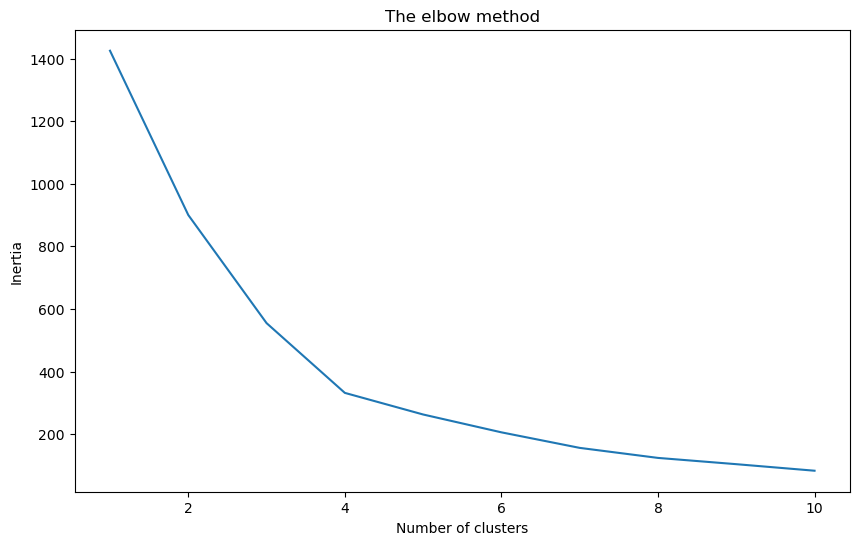

In [19]:
inertia = plot_inertia(reduced)

Based on the elbow plot we use 4 clusters. `plot_pair()` shows the clusters on the first four principal components.

In [20]:
def plot_pair(reduced, clusters):
    '''
    Uses seaborn.PairGrid to visualize the data distribution
    when axes are the first four principal components.
    Diagonal plots are histograms. The off-diagonal plots are scatter plots.
    
    Parameters
    ----------
    reduced: A numpy array. Comes from importing delta_reduced.npy
    
    Returns
    -------
    A seaborn.axisgrid.PairGrid instance.
    '''
    
    df = pd.DataFrame(reduced)
    df['c'] = clusters
    subset = [0,1,2,3, 'c']
    columns = [0,1,2,3]
    
    ax = sns.PairGrid(df[subset], vars = columns, hue = 'c')
    ax = ax.map_diag(plt.hist)
    ax = ax.map_offdiag(plt.scatter)
    
    return ax

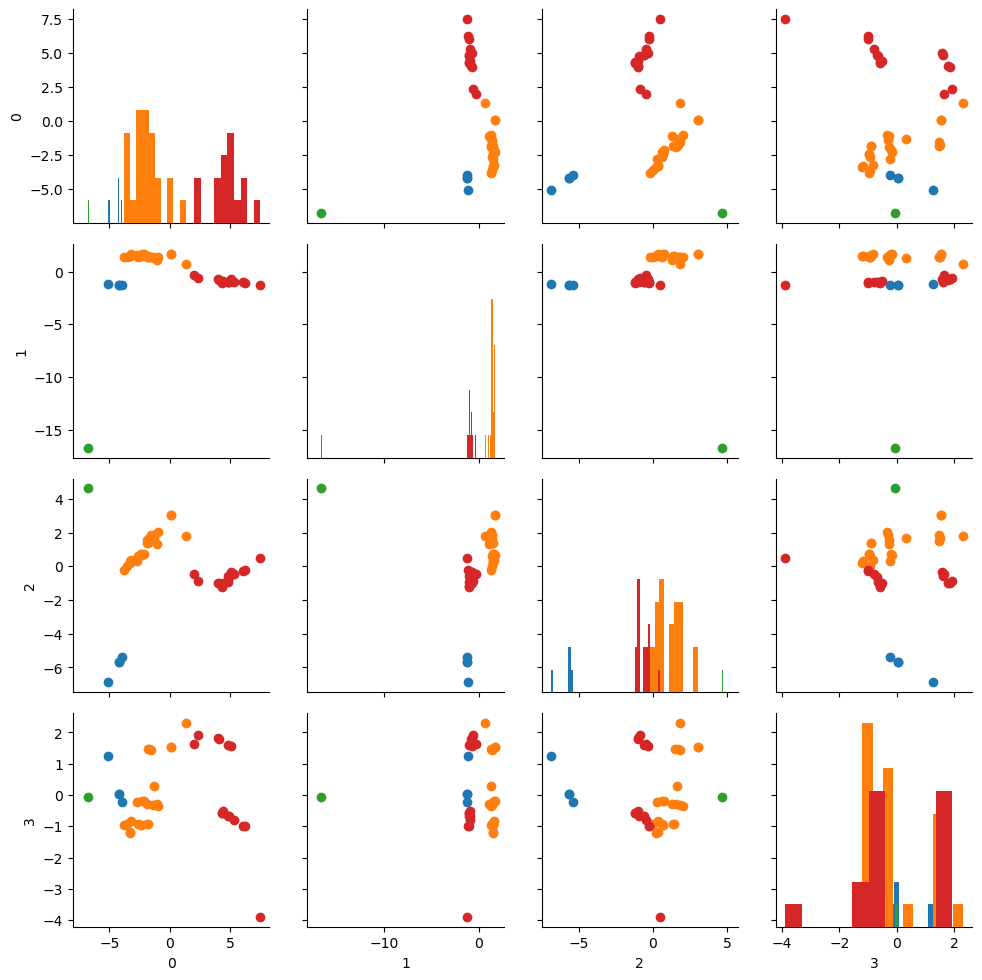

In [21]:
k_means, clusters = cluster(reduced, random_state=check_random_state(0), n_clusters=4)
pg = plot_pair(reduced, clusters)

We observe that the one outlier is in its own cluster, there’s 3 or 4 points in the other clusters and the remainder are split into two clusters of greater size.

#### Cluster profiles
Let's take a closer look at each cluster. (K-means cluster numbers are arbitrary labels; the numbers below refer to the output of this run.)

In [22]:
df = pd.read_csv('data/delta.csv', index_col='Aircraft')
df['Clusters'] = clusters
df['Aircraft'] = df.index
df_grouped = df.groupby('Clusters').mean(numeric_only=True)
print(df_grouped.Accommodation)

Clusters
0     44.500000
1    153.625000
2     54.000000
3    244.733333
Name: Accommodation, dtype: float64


In [23]:
print(df_grouped['Length (ft)'])

Clusters
0     84.810750
1    137.048083
2    111.000000
3    190.538400
Name: Length (ft), dtype: float64


Cluster 2 has only one aircraft:

In [24]:
vip_cluster = df[df.Clusters == 2]
print(vip_cluster.Aircraft)

Aircraft
Airbus A319 VIP    Airbus A319 VIP
Name: Aircraft, dtype: object


Airbus A319 VIP is not one of Delta Air Lines' regular fleet and is one of Airbus' corporate jets.

Cluster 0 has four aircraft.

In [25]:
regional_cluster = df[df.Clusters == 0]
print(regional_cluster.Aircraft)

Aircraft
CRJ 100/200 Pinnacle/SkyWest    CRJ 100/200 Pinnacle/SkyWest
CRJ 100/200 ExpressJet                CRJ 100/200 ExpressJet
E120                                                    E120
ERJ-145                                              ERJ-145
Name: Aircraft, dtype: object


These are small aircraft and only have economy seats.

In [26]:
cols_seat = ['First Class', 'Business', 'Eco Comfort', 'Economy']
print(df.loc[regional_cluster.index, cols_seat])

                              First Class  Business  Eco Comfort  Economy
Aircraft                                                                 
CRJ 100/200 Pinnacle/SkyWest            0         0            0        1
CRJ 100/200 ExpressJet                  0         0            0        1
E120                                    0         0            0        1
ERJ-145                                 0         0            0        1


In [27]:
longhaul_cluster = df[df.Clusters == 3]
print(longhaul_cluster.Aircraft)

Aircraft
Airbus A330-200                      Airbus A330-200
Airbus A330-200 (3L2)          Airbus A330-200 (3L2)
Airbus A330-200 (3L3)          Airbus A330-200 (3L3)
Airbus A330-300                      Airbus A330-300
Boeing 747-400 (74S)            Boeing 747-400 (74S)
Boeing 757-200 (75E)            Boeing 757-200 (75E)
Boeing 757-200 (75X)            Boeing 757-200 (75X)
Boeing 767-300 (76G)            Boeing 767-300 (76G)
Boeing 767-300 (76L)            Boeing 767-300 (76L)
Boeing 767-300 (76T)            Boeing 767-300 (76T)
Boeing 767-300 (76Z V.1)    Boeing 767-300 (76Z V.1)
Boeing 767-300 (76Z V.2)    Boeing 767-300 (76Z V.2)
Boeing 767-400 (76D)            Boeing 767-400 (76D)
Boeing 777-200ER                    Boeing 777-200ER
Boeing 777-200LR                    Boeing 777-200LR
Name: Aircraft, dtype: object


Interestingly, the cluster 3 aircraft do not have first class seating.

In [28]:
print(df.loc[longhaul_cluster.index, cols_seat])

                          First Class  Business  Eco Comfort  Economy
Aircraft                                                             
Airbus A330-200                     0         1            1        1
Airbus A330-200 (3L2)               0         1            1        1
Airbus A330-200 (3L3)               0         1            1        1
Airbus A330-300                     0         1            1        1
Boeing 747-400 (74S)                0         1            1        1
Boeing 757-200 (75E)                0         1            1        1
Boeing 757-200 (75X)                0         1            1        1
Boeing 767-300 (76G)                0         1            1        1
Boeing 767-300 (76L)                0         1            1        1
Boeing 767-300 (76T)                0         1            1        1
Boeing 767-300 (76Z V.1)            0         1            1        1
Boeing 767-300 (76Z V.2)            0         1            1        1
Boeing 767-400 (76D)

In [29]:
domestic_cluster = df[df.Clusters == 1]
print(domestic_cluster.Aircraft)

Aircraft
Airbus A319                          Airbus A319
Airbus A320                          Airbus A320
Airbus A320 32-R                Airbus A320 32-R
Boeing 717                            Boeing 717
Boeing 737-700 (73W)        Boeing 737-700 (73W)
Boeing 737-800 (738)        Boeing 737-800 (738)
Boeing 737-800 (73H)        Boeing 737-800 (73H)
Boeing 737-900ER (739)    Boeing 737-900ER (739)
Boeing 757-200 (75A)        Boeing 757-200 (75A)
Boeing 757-200 (75M)        Boeing 757-200 (75M)
Boeing 757-200 (75N)        Boeing 757-200 (75N)
Boeing 757-200 (757)        Boeing 757-200 (757)
Boeing 757-200 (75V)        Boeing 757-200 (75V)
Boeing 757-300                    Boeing 757-300
Boeing 767-300 (76P)        Boeing 767-300 (76P)
Boeing 767-300 (76Q)        Boeing 767-300 (76Q)
Boeing 767-300 (76U)        Boeing 767-300 (76U)
CRJ 700                                  CRJ 700
CRJ 900                                  CRJ 900
E170                                        E170
E175       

The aircraft in cluster 1 (except for one aircraft) have first class seating but no business class.

In [30]:
print(df.loc[domestic_cluster.index, cols_seat])

                        First Class  Business  Eco Comfort  Economy
Aircraft                                                           
Airbus A319                       1         0            1        1
Airbus A320                       1         0            1        1
Airbus A320 32-R                  1         0            1        1
Boeing 717                        1         0            1        1
Boeing 737-700 (73W)              1         0            1        1
Boeing 737-800 (738)              1         0            1        1
Boeing 737-800 (73H)              1         0            1        1
Boeing 737-900ER (739)            1         0            1        1
Boeing 757-200 (75A)              1         0            1        1
Boeing 757-200 (75M)              1         0            1        1
Boeing 757-200 (75N)              1         0            1        1
Boeing 757-200 (757)              1         0            1        1
Boeing 757-200 (75V)              1         0   

## 3. Comparing K-Means, DBSCAN and Hierarchical Clustering

- **3.1** DBSCAN vs. K-Means on the Iris dataset
- **3.2** DBSCAN vs. K-Means on the Delta PCA components
- **3.3** K-Means vs. DBSCAN vs. hierarchical (agglomerative) clustering on stock-price movements

Clusterings are compared with crosstabs against reference labels and with the silhouette score.

In [31]:
def compute_silhouette(X, labels):

    mask = labels != -1
    X_clean = X[mask]
    labels_clean = labels[mask]

    if len(np.unique(labels_clean)) < 2:
        return np.nan

    return silhouette_score(X_clean, labels_clean)

### 3.1 Iris

In [32]:
df = pd.read_csv("data/Iris.csv")
X = df.drop(columns=["Species", "Id"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [33]:
X.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [34]:
y = df["Species"]
df["Species"].unique()

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

In [35]:
kmeans = KMeans(n_clusters=3, random_state=0, n_init=10) #Selected 3 clusters because that is the number of species
kmeans_labels = kmeans.fit_predict(X_scaled)

To choose `eps` for DBSCAN, we look at the k-distance graph for several values of `min_samples`.

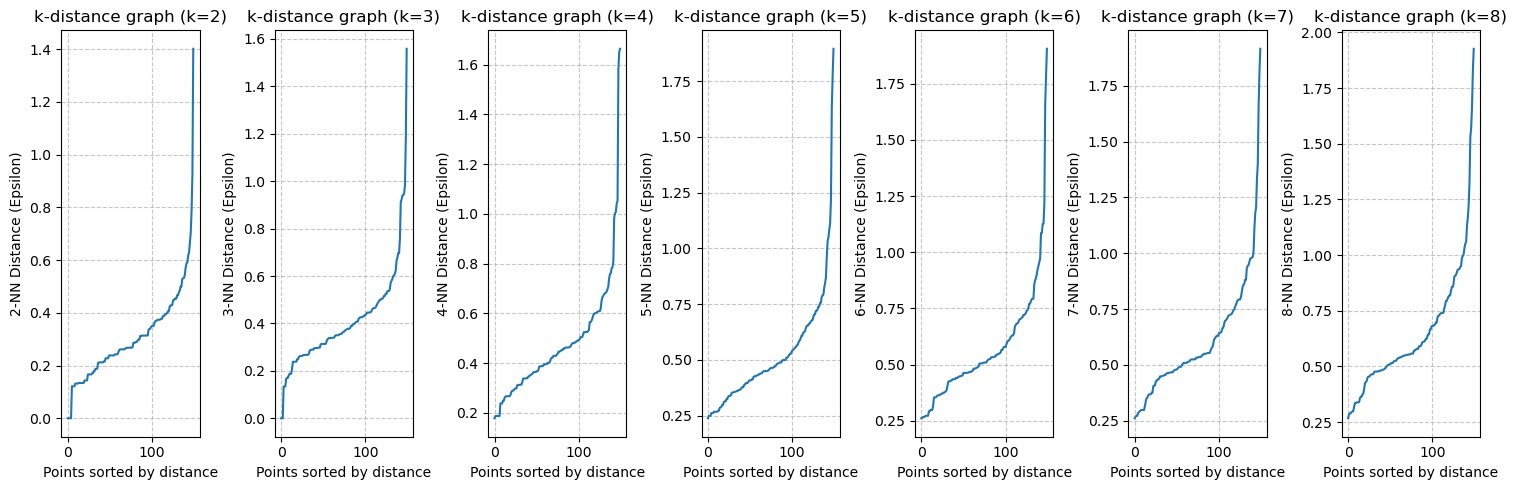

In [36]:
min_samples_list = [2, 3, 4, 5, 6, 7, 8]

plt.figure(figsize=(15, 5))

for i, k in enumerate(min_samples_list):
    neigh = NearestNeighbors(n_neighbors=k)
    nbrs = neigh.fit(X_scaled)
    distances, indices = nbrs.kneighbors(X_scaled)

    k_distances = np.sort(distances[:, k-1], axis=0)

    plt.subplot(1, 7, i+1)
    plt.plot(k_distances)
    plt.title(f'k-distance graph (k={k})')
    plt.xlabel('Points sorted by distance')
    plt.ylabel(f'{k}-NN Distance (Epsilon)')
    plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [37]:
dbscan = DBSCAN(eps=0.45, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

In [38]:
kmeans_crosstab = pd.crosstab(
    y,
    kmeans_labels,
    rownames=["True Species"],
    colnames=["K-Means Cluster"]
)

print(kmeans_crosstab)

K-Means Cluster   0   1   2
True Species               
Iris-setosa       0  50   0
Iris-versicolor  39   0  11
Iris-virginica   14   0  36


In [39]:
sil_km = compute_silhouette(X_scaled, kmeans_labels)
print("K-Means silhouette:", sil_km)

K-Means silhouette: 0.4589717867018717


In [40]:
dbscan_crosstab = pd.crosstab(
    y,
    dbscan_labels,
    rownames=["True Species"],
    colnames=["DBSCAN Cluster"]
)

print(dbscan_crosstab)

DBSCAN Cluster   -1   0   1   2
True Species                   
Iris-setosa      10  40   0   0
Iris-versicolor  13   0  37   0
Iris-virginica   34   0   1  15


In [41]:
sil_db = compute_silhouette(X_scaled, dbscan_labels)
print("DBSCAN silhouette:", sil_db)

DBSCAN silhouette: 0.5488212345348525


For K-Means I chose K based on the number of species for Iris dataset, meanwhile for DBScan I tried first to look at the elbow plot, but then started running it with different parameters and didn't really find an optimal one like I was hoping, because it seems that Iris-versicolor and virginica can have very similar features and that makes it hard to differentiate the two, so I either ended up with a DBScan classification that grouped those two together or managed to separate them but end up with a lot of noise like it was in this last configuration I have. KMeans also has the same problem of confusing these 2 species. And if we take silhouette score it would seem DBScan is better but that isn't taking into consideration the noise, so it isn't easy to answer which method is better in this case.

### 3.2 Delta PCA components
Here the reference labels are the 4 K-Means clusters from Section 2.

In [42]:
df = pd.DataFrame(reduced)
df['c'] = clusters
df.head(10)

,0,1,2,3,4,5,6,7,8,9,c
0,-2.656021,1.382411,0.604632,-0.937262,-0.833086,-0.161946,0.154810,0.026209,-0.278241,-0.242456,1
1,-6.766622,-16.743734,4.634099,-0.080052,-0.173567,-0.122512,0.005508,-0.152932,-0.025015,0.070355,2
2,-2.396654,1.487692,0.707971,-0.969813,-0.701819,0.056788,0.082178,-0.043574,-0.557341,-0.085647,1
3,-2.396654,1.487692,0.707971,-0.969813,-0.701819,0.056788,0.082178,-0.043574,-0.557341,-0.085647,1
4,4.862387,-0.951892,-0.619606,-0.679016,0.210635,-0.775235,-0.955583,0.135180,0.038378,0.174469,3
5,4.835659,-0.982179,-0.584933,1.609885,-1.595654,0.705254,0.696404,0.339816,-0.459014,-0.014388,3
6,5.322492,-0.929381,-0.450332,-0.793325,0.405473,-0.505964,-0.905826,-0.185134,-0.622420,0.518551,3
7,5.018201,-0.725626,-0.320057,1.558384,-1.203502,1.251844,0.674960,0.103043,-1.175149,0.489031,3
8,-2.752771,1.593377,0.315268,-0.225288,-0.568519,-0.788330,0.520195,-1.077356,0.630571,0.964505,1
9,-1.812486,1.370897,1.509489,1.456903,1.615354,-1.418187,0.725098,0.426127,0.743837,-0.370731,1


In [43]:
y = df['c']

In [44]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(reduced)

In [45]:
kmeans = KMeans(n_clusters=4, random_state=0, n_init=10) # 4 clusters, the same number as in Section 2
kmeans_labels = kmeans.fit_predict(X_scaled)

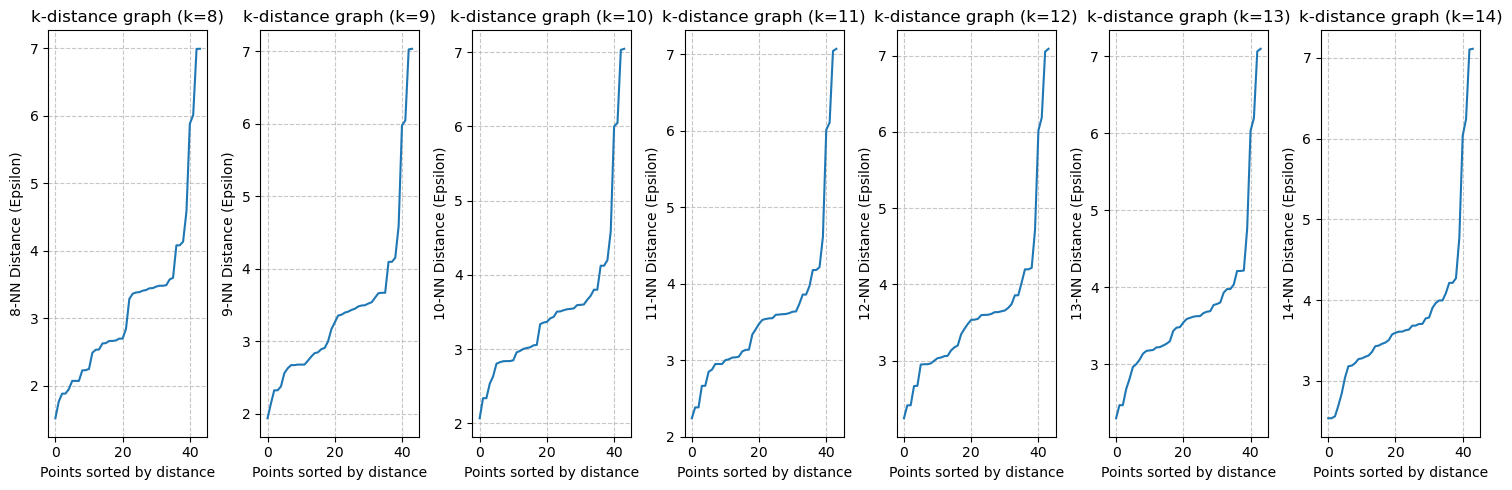

In [46]:
min_samples_list = [8, 9, 10, 11, 12, 13, 14]

plt.figure(figsize=(15, 5))

for i, k in enumerate(min_samples_list):
    neigh = NearestNeighbors(n_neighbors=k)
    nbrs = neigh.fit(X_scaled)
    distances, indices = nbrs.kneighbors(X_scaled)

    k_distances = np.sort(distances[:, k-1], axis=0)

    plt.subplot(1, 7, i+1)
    plt.plot(k_distances)
    plt.title(f'k-distance graph (k={k})')
    plt.xlabel('Points sorted by distance')
    plt.ylabel(f'{k}-NN Distance (Epsilon)')
    plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [47]:
dbscan = DBSCAN(eps=3.2, min_samples=3)
dbscan_labels = dbscan.fit_predict(X_scaled)

In [48]:
kmeans_crosstab = pd.crosstab(
    y,
    kmeans_labels,
    rownames=["Section 2 Cluster"],
    colnames=["K-Means Cluster"]
)

print(kmeans_crosstab)

K-Means Cluster    0   1  2  3
Section 2 Cluster             
0                  0   4  0  0
1                  0  18  6  0
2                  0   0  0  1
3                  8   6  1  0


In [49]:
sil_km = compute_silhouette(X_scaled, kmeans_labels)
print("K-Means silhouette:", sil_km)

K-Means silhouette: 0.15012416828609307


In [50]:
for eps in [3.2, 3.0, 2.8, 2.6]:
    labels = DBSCAN(eps=eps, min_samples=3).fit_predict(X_scaled)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise = (labels == -1).mean()
    print(f"eps={eps}: clusters={n_clusters}, noise={noise:.2f}")

eps=3.2: clusters=3, noise=0.09
eps=3.0: clusters=3, noise=0.11
eps=2.8: clusters=3, noise=0.16
eps=2.6: clusters=4, noise=0.16


In [51]:
dbscan_crosstab = pd.crosstab(
    y,
    dbscan_labels,
    rownames=["Section 2 Cluster"],
    colnames=["DBSCAN Cluster"]
)

print(dbscan_crosstab)

DBSCAN Cluster     -1   0   1   2
Section 2 Cluster                
0                   1   0   0   3
1                   1  23   0   0
2                   1   0   0   0
3                   1   9   5   0


In [52]:
sil_db = compute_silhouette(X_scaled, dbscan_labels)
print("DBSCAN silhouette:", sil_db)

DBSCAN silhouette: 0.2716391390154641


I did the same thing here as in the last example, first use KMeans with the number of clusters that we know exist, and then I tried DBscan with the elbow method and then started experimenting with different parameters and this was the best I found. Here it is grouping in a cluster airplanes from cluster 1 and 3. Also since cluster 2 only has one data point in its cluster we end up with it just being categorized as noise. DBScan predicts cluster 0 and 1 almost perfectly with just one point taken as noise, in comparison cluster 1 in KMeans gets split into 2. I would trust the silhouette score here a bit more since we have less points as noise and say maybe DBScan performs a little better, but it all depends on how we are judging them.

### 3.3 Stock-price movements
Daily price movements of 60 large companies (963 trading days, January 2010 to October 2013). Each company's movement vector is normalized so that companies are compared on the shape of their movements rather than on their price level.

In [53]:
df = pd.read_csv('data/movements.csv', index_col=0)
companies = df.index.values
movements = df.values

normalizer = Normalizer()
normalized_movements = normalizer.fit_transform(movements)

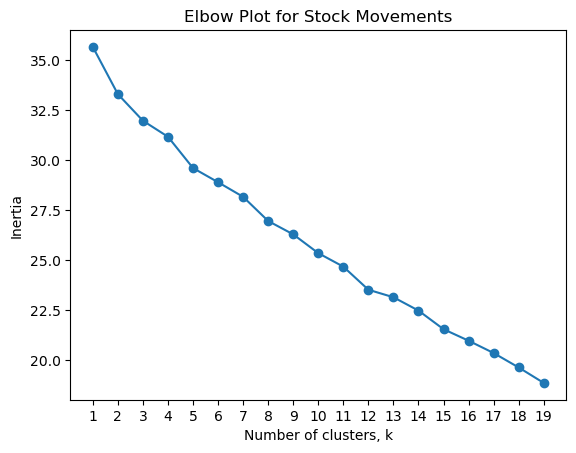

In [54]:
ks = range(1, 20)
inertias = []

for k in ks:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(normalized_movements)
    inertias.append(model.inertia_)

plt.plot(ks, inertias, '-o')
plt.xlabel('Number of clusters, k')
plt.ylabel('Inertia')
plt.title('Elbow Plot for Stock Movements')
plt.xticks(ks)
plt.show()

In [55]:
kmeans = KMeans(n_clusters=10, random_state=42, n_init=10)
labels = kmeans.fit_predict(normalized_movements)

df_clusters = pd.DataFrame({'Company': companies, 'Cluster': labels})
df_clusters = df_clusters.sort_values(by='Cluster')

print(df_clusters)

                               Company  Cluster
3                     American express        0
55                         Wells Fargo        0
30                          MasterCard        0
25                   Johnson & Johnson        1
27                      Kimberly-Clark        1
40                      Procter Gamble        1
28                           Coca Cola        1
56                            Wal-Mart        1
41                       Philip Morris        1
38                               Pepsi        1
9                    Colgate-Palmolive        1
15                                Ford        2
35                            Navistar        2
1                                  AIG        2
46                      Sanofi-Aventis        3
43                                 SAP        3
37                            Novartis        3
52                            Unilever        3
19                     GlaxoSmithKline        3
6             British American Tobacco  

In [56]:
sil_km = compute_silhouette(normalized_movements, labels)
print("K-Means silhouette:", sil_km)

K-Means silhouette: 0.03614071478711508


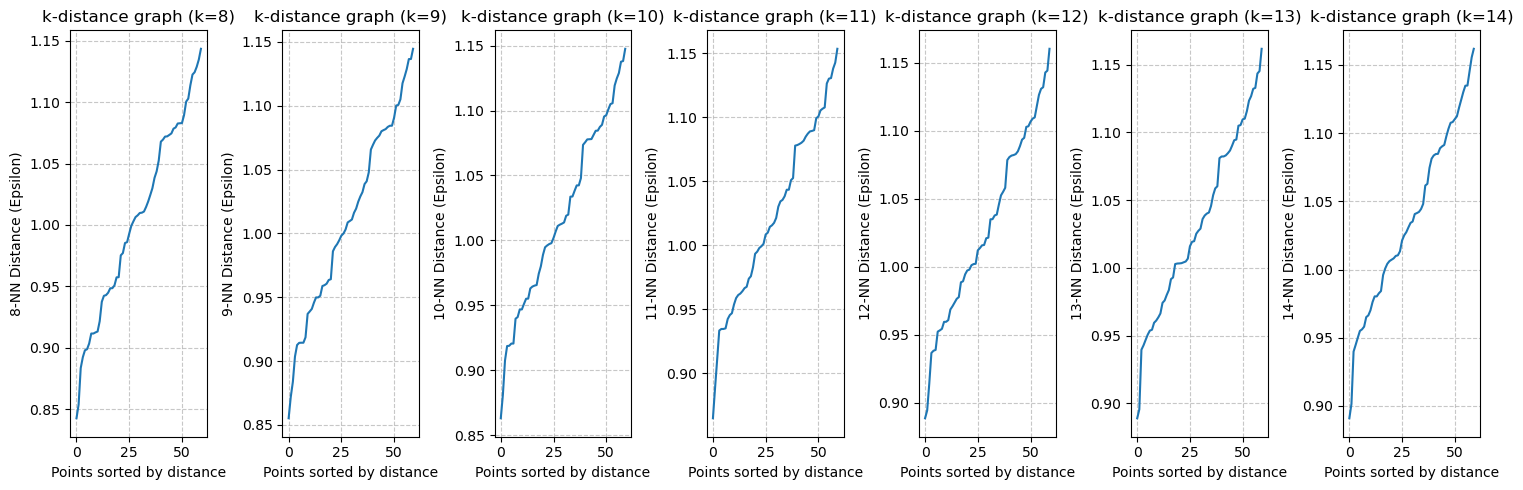

In [57]:
min_samples_list = [8, 9, 10, 11, 12, 13, 14]

plt.figure(figsize=(15, 5))

for i, k in enumerate(min_samples_list):
    neigh = NearestNeighbors(n_neighbors=k)
    nbrs = neigh.fit(normalized_movements)
    distances, indices = nbrs.kneighbors(normalized_movements)

    k_distances = np.sort(distances[:, k-1], axis=0)

    plt.subplot(1, 7, i+1)
    plt.plot(k_distances)
    plt.title(f'k-distance graph (k={k})')
    plt.xlabel('Points sorted by distance')
    plt.ylabel(f'{k}-NN Distance (Epsilon)')
    plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [58]:
dbscan = DBSCAN(eps=.95, min_samples=2)
dbscan_labels = dbscan.fit_predict(normalized_movements)

df_results = pd.DataFrame({'Company': df.index, 'Cluster': dbscan_labels})
print(df_results.sort_values(by='Cluster'))

                               Company  Cluster
0                                Apple       -1
23                                 IBM       -1
25                   Johnson & Johnson       -1
28                           Coca Cola       -1
58                               Xerox       -1
30                          MasterCard       -1
31                           McDonalds       -1
33                           Microsoft       -1
22                                  HP       -1
35                            Navistar       -1
39                              Pfizer       -1
41                       Philip Morris       -1
47                            Symantec       -1
50  Taiwan Semiconductor Manufacturing       -1
53                       Valero Energy       -1
54                            Walgreen       -1
56                            Wal-Mart       -1
38                               Pepsi       -1
20                          Home Depot       -1
59                               Yahoo  

In [59]:
sil_db = compute_silhouette(normalized_movements, dbscan_labels)
print("DBSCAN silhouette:", sil_db)

DBSCAN silhouette: 0.08800425342180417


Finally, hierarchical (agglomerative) clustering with Ward linkage:

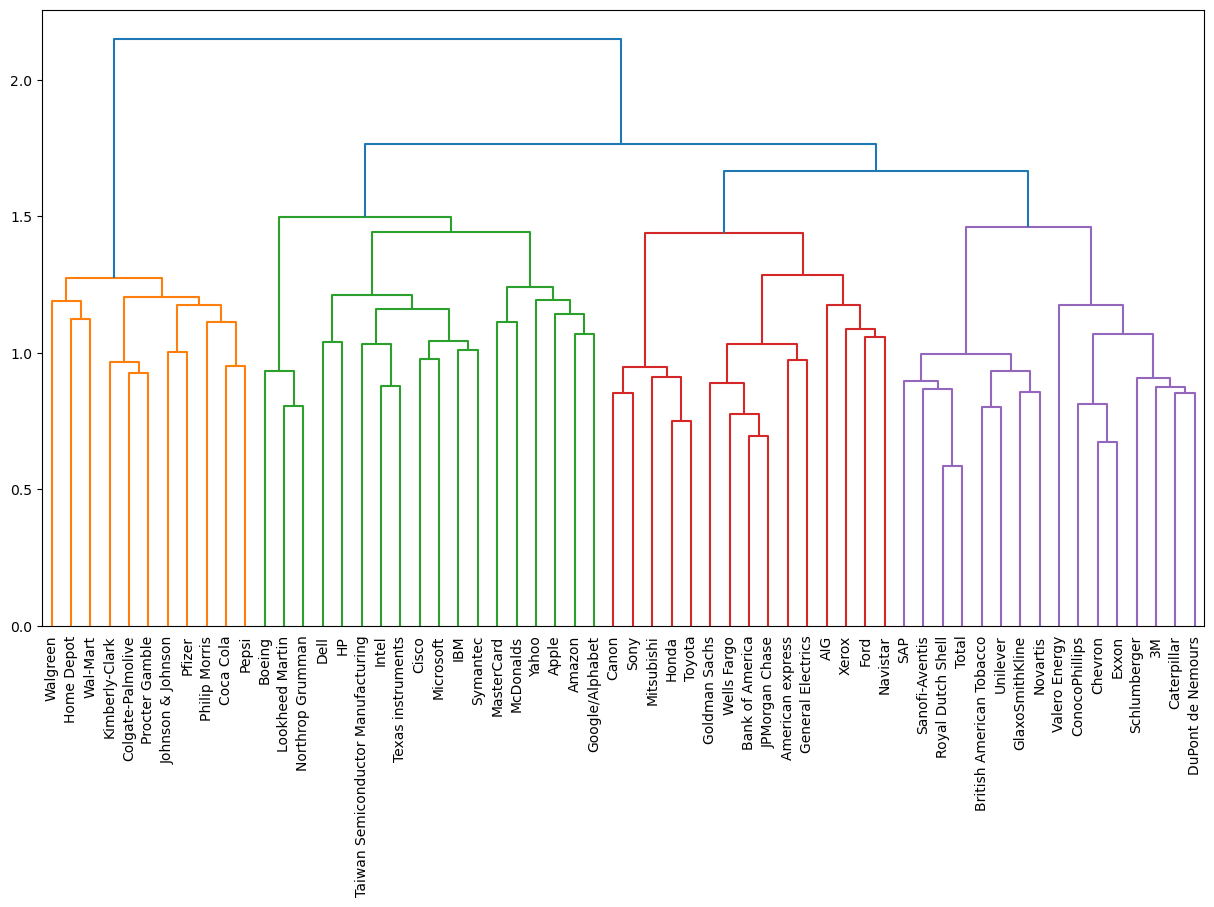

In [60]:
mergings = linkage(normalized_movements, method='ward')

plt.figure(figsize=(15, 8))
dendrogram(mergings, labels=df.index, leaf_rotation=90, leaf_font_size=10)
plt.show()

In [61]:
labels = fcluster(mergings, t=4, criterion='maxclust')

pairs = pd.DataFrame({'labels': labels, 'companies': df.index})
print(pairs.sort_values('labels'))

    labels                           companies
38       1                               Pepsi
56       1                            Wal-Mart
54       1                            Walgreen
25       1                   Johnson & Johnson
41       1                       Philip Morris
40       1                      Procter Gamble
39       1                              Pfizer
9        1                   Colgate-Palmolive
20       1                          Home Depot
27       1                      Kimberly-Clark
28       1                           Coca Cola
23       2                                 IBM
24       2                               Intel
30       2                          MasterCard
0        2                               Apple
33       2                           Microsoft
36       2                    Northrop Grumman
47       2                            Symantec
50       2  Taiwan Semiconductor Manufacturing
51       2                   Texas instruments
31       2   

Here I tried various different parameters for DBScan, but none seemed as good as KMeans or Hierarchical Clustering. I think for this type of data Hierarchical was the best method, because not only could it cluster the companies but also help us understand in that cluster which companies are more closely related to which other companies. For example, it put Coca-Cola and Pepsi closer together than other companies in that same cluster.

## 4. t-SNE and UMAP vs. PCA

Next we apply t-SNE (and UMAP) to the Delta data and compare the 2-D embeddings with PCA.

In [62]:
df = pd.read_csv('data/delta.csv')
labels = df['Aircraft']
features = df.drop('Aircraft', axis=1)

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

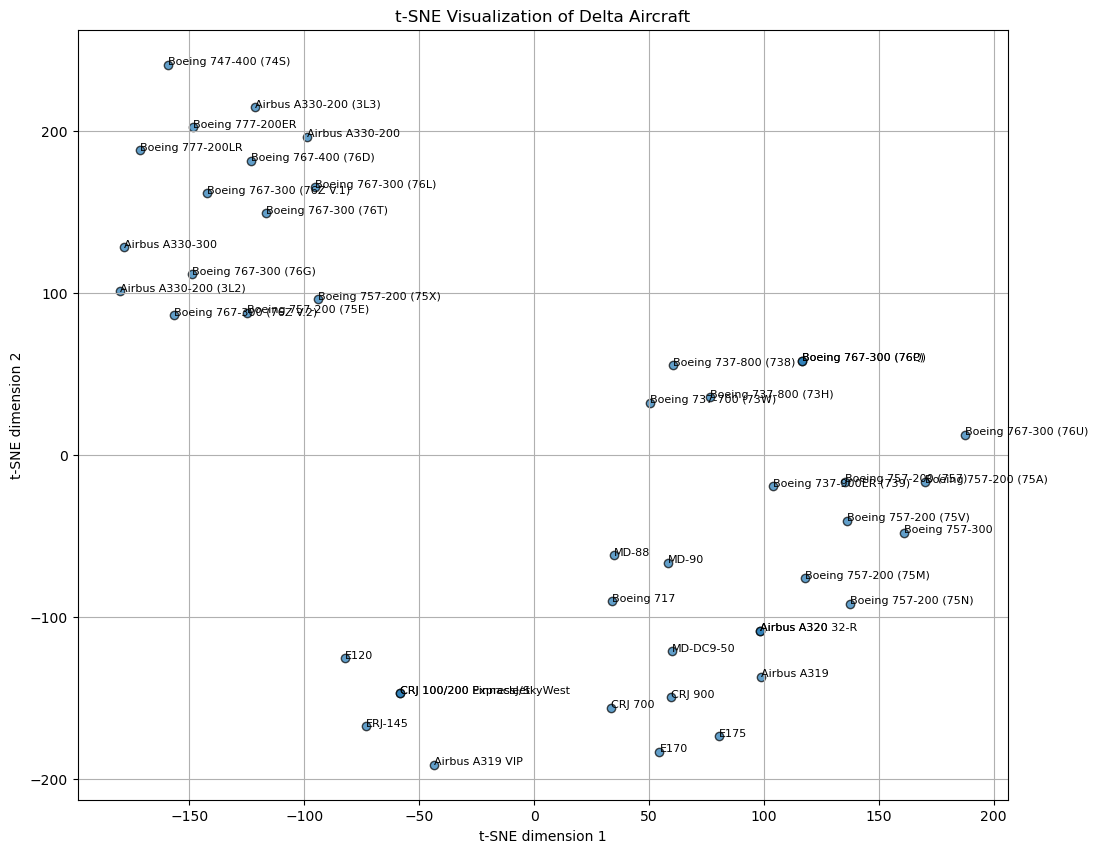

In [63]:
tsne = TSNE(n_components=2, perplexity=10, random_state=42, learning_rate='auto')
tsne_results = tsne.fit_transform(features_scaled)

plt.figure(figsize=(12, 10))
plt.scatter(tsne_results[:, 0], tsne_results[:, 1], alpha=0.7, edgecolors='k')

for i, txt in enumerate(labels):
    plt.annotate(txt, (tsne_results[i, 0], tsne_results[i, 1]), fontsize=8)

plt.title('t-SNE Visualization of Delta Aircraft')
plt.xlabel('t-SNE dimension 1')
plt.ylabel('t-SNE dimension 2')
plt.grid(True)
plt.show()

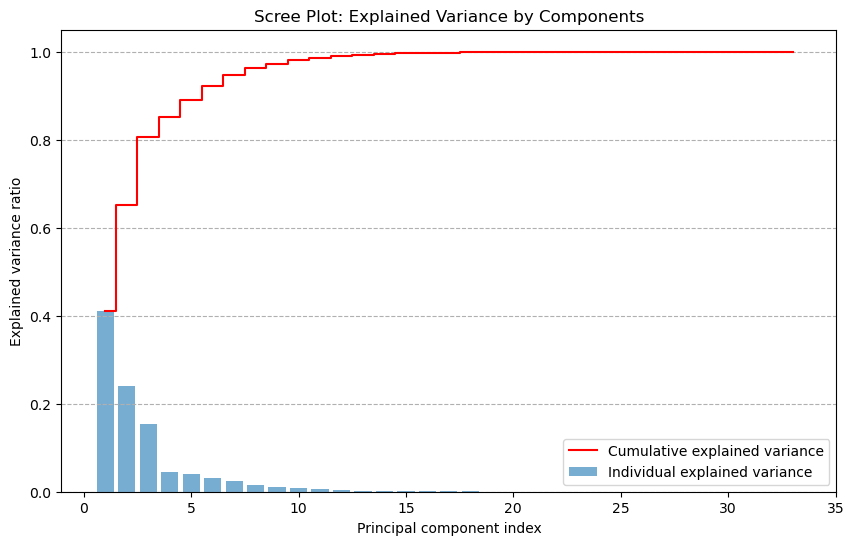

In [64]:
pca = PCA()
pca.fit(features_scaled)
exp_var_ratio = pca.explained_variance_ratio_

plt.figure(figsize=(10, 6))

plt.bar(range(1, len(exp_var_ratio) + 1), exp_var_ratio, alpha=0.6,
        label='Individual explained variance')

plt.step(range(1, len(exp_var_ratio) + 1), np.cumsum(exp_var_ratio), where='mid',
         label='Cumulative explained variance', color='red')

plt.ylabel('Explained variance ratio')
plt.xlabel('Principal component index')
plt.title('Scree Plot: Explained Variance by Components')
plt.legend(loc='best')
plt.grid(axis='y', linestyle='--')
plt.show()

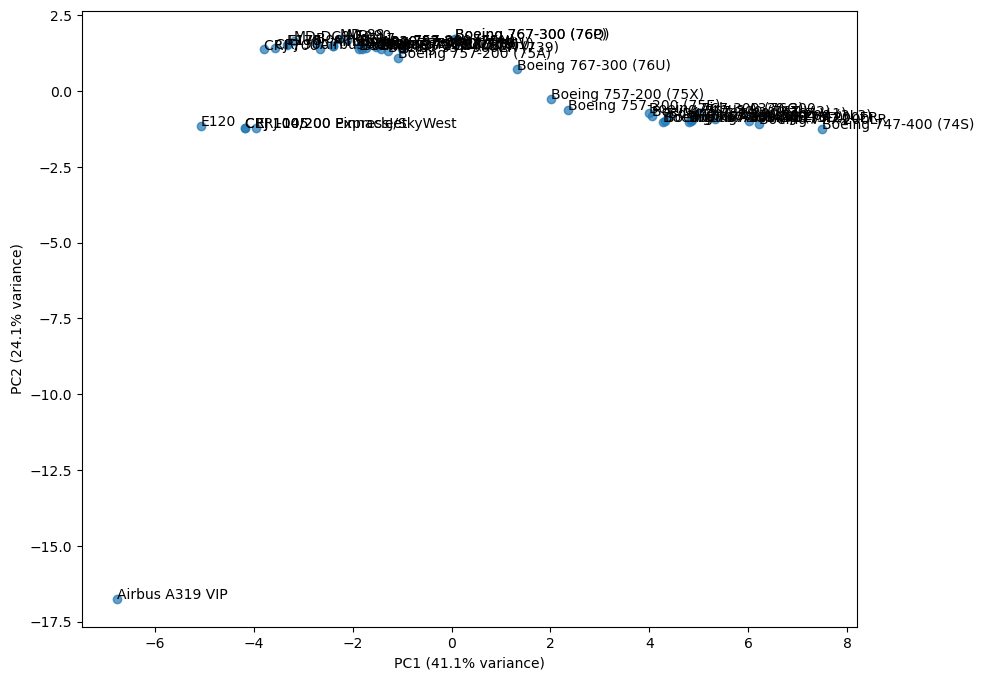

In [65]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(features_scaled)

plt.figure(figsize=(10, 8))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.7)
for i, name in enumerate(df['Aircraft']):
    plt.annotate(name, (X_pca[i, 0], X_pca[i, 1]))

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
plt.show()

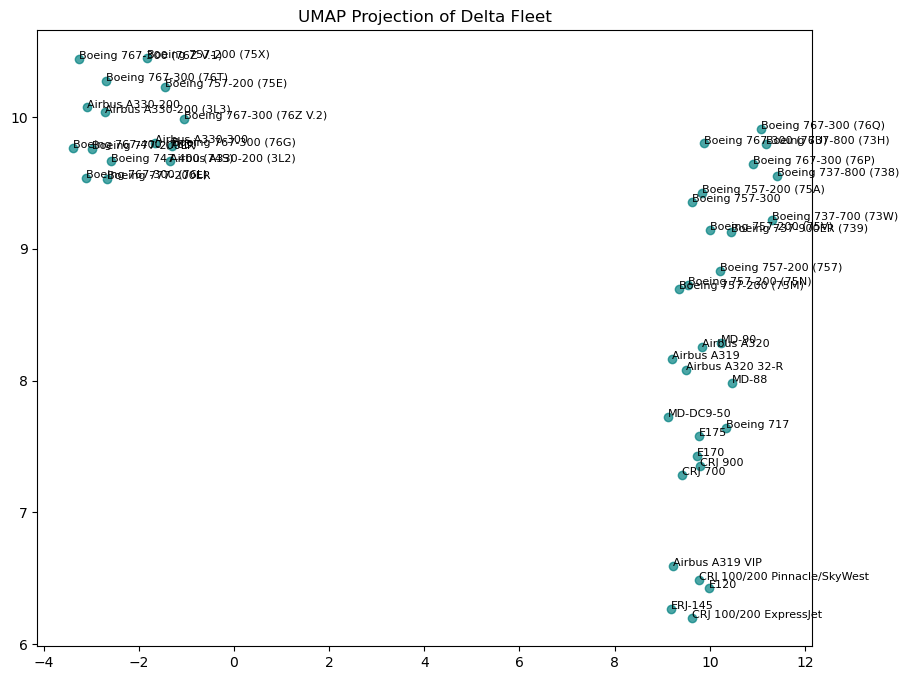

In [66]:
# 1. Load and Scale
df = pd.read_csv('data/delta.csv')
X = df.drop('Aircraft', axis=1)
X_scaled = StandardScaler().fit_transform(X)

# 2. Apply UMAP
# n_neighbors: similar to t-SNE's perplexity (local vs global focus)
# min_dist: how tightly points are allowed to pack together
reducer = umap.UMAP(n_neighbors=15,
                    min_dist=0.1,
                    n_components=2,
                    random_state=42)

embedding = reducer.fit_transform(X_scaled)

# 3. Visualize
plt.figure(figsize=(10, 8))
plt.scatter(embedding[:, 0], embedding[:, 1], alpha=0.7, c='teal')

for i, txt in enumerate(df['Aircraft']):
    plt.annotate(txt, (embedding[i, 0], embedding[i, 1]), fontsize=8)

plt.title('UMAP Projection of Delta Fleet')
plt.show()

Here t-SNE is better for finding clusters in the data, in the PCA chart almost everything is so close together that it is hard to differentiate. For PCA the first 3 principal components account for around 80% of the total variance. Since PCA preserves the global structure better we can see that Airbus A319 VIP is a very different aircraft from the others, we don't get that same information in the t-SNE plot.

## 5. Hierarchical Clustering of the Delta Fleet

Applying hierarchical clustering (Ward linkage) to the standardized Delta data shows which aircraft are grouped together first, at the bottom of the dendrogram.

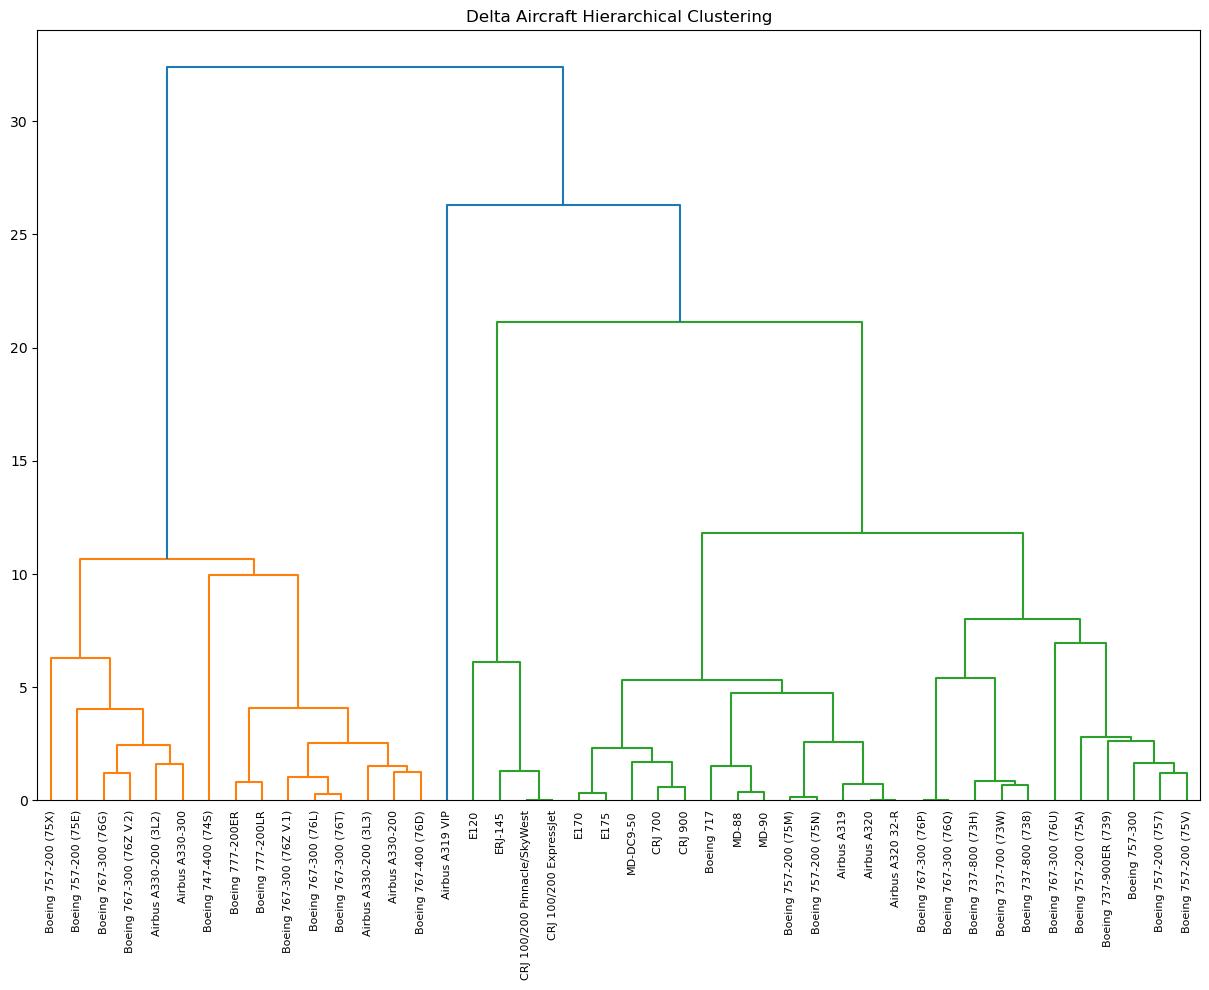

In [67]:
mergings = linkage(X_scaled, method='ward')

plt.figure(figsize=(15, 10))
dendrogram(mergings, labels=df['Aircraft'].values, leaf_rotation=90)
plt.title('Delta Aircraft Hierarchical Clustering')
plt.show()

The dendrogram helps us to not only cluster the data but see how similar aircrafts are to one another, for example, Boeing 767-300 (76P) and (76Q) are very close together as they should be. And again we have Airbus A319 VIP on its own.